In [77]:
print("test kernel")

test kernel


In [78]:
import numpy as np
import matplotlib.pyplot as plt
from baseframework import datahandler
from baseframework.offline_clustering.adjacency import adjacency_clustering

[[0.68479944 0.24851561]
 [0.3001912  0.76540947]
 [0.61570754 0.61467317]
 [0.70614274 0.32031927]
 [0.26602823 0.69761609]]
[0 1 2 0 1]


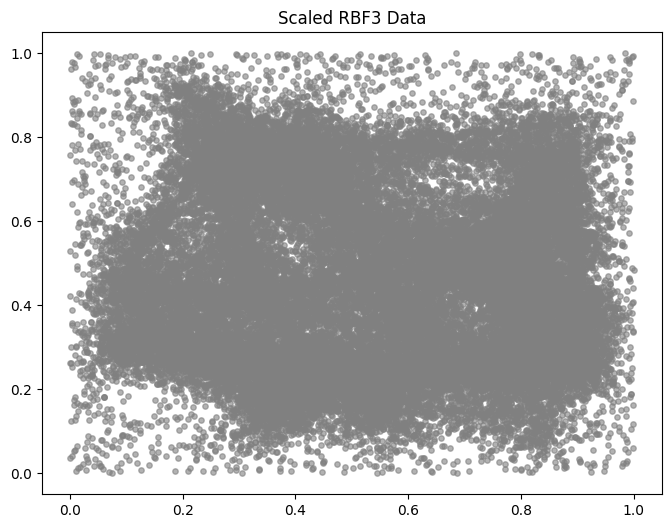

In [24]:
import sys
sys.path.insert(0, '/Users/felix/Desktop/Local/Uni/SoSe26/Stream Clustering/dstream-hajuj/baseframework')
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# 1. Load the data using the handler
# This gives us the scaled features (X) and the ground truth labels (y)
X, y_true = datahandler.load_data("rbf3")
print(X[0:5])
print(y_true[0:5])

# Plot it quickly 
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=15, c='gray', alpha=0.6)
plt.title("Scaled RBF3 Data")
plt.show()

In [80]:
print(X[0])
print(X[0][0])


[0.68479944 0.24851561]
0.6847994357638937


K-Means Clustering: The Baseline

K-Means is arguably the most famous traditional clustering algorithm. Its core idea is to find a clustering such that the within-cluster variation is small, using the geometric center (the "centroid" or mean) of a cluster as its representative.

Specifically, K-Means tries to minimize the sum of the squared distances between the cluster means and their respective elements.



Strengths and Weaknesses

Strengths:

• Efficiency: It is relatively efficient with a time complexity of $O(tkn)$ (where $t$ is iterations, $k$ is the number of clusters, and $n$ is the number of objects).

• Simplicity: It is known for its easy implementation.

Weaknesses:

• The $k$ problem: You are forced to specify $k$, the number of clusters, in advance. If you guess wrong, the clustering will be poor.

• Shape limitations: Clusters are forced into convex space partitions (known as Voronoi Cells). This means it struggles with any data that isn't roughly spherical.

• Sensitivity: It is highly sensitive to noisy data and outliers. Because it uses the "mean" to find the center, a single extreme outlier can drag the centroid far away from the true dense group.

• Initial luck: The final result and the runtime strongly depend on the initial random placement of the centroids; it often gets stuck in a "local optimum" (a result that looks mathematically okay to the algorithm but isn't the best possible grouping)

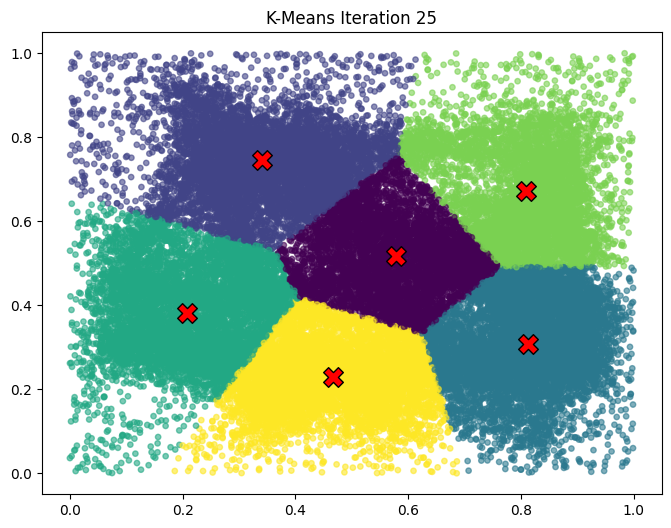

In [26]:

def run_interactive_kmeans(X, k, max_iters=10):
    # TODO: 1. Initialization
    # Randomly select 'k' points from X to be your initial centroids.
    centroids = X[np.random.choice(X.shape[0], size=k, replace=False), :]
    print("Centroids: ", centroids)
    #centroids = X[np.random.randint(X.shape[0], size=k), :]

    
    for i in range(max_iters):
        # TODO: 2. Assignment Phase
        # Calculate the distance between EVERY point in X and EVERY centroid.
        # Assign each point to the index of the closest centroid.
        # 'labels' should be an array of length len(X) containing integers from 0 to k-1.
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        
        # --- Visualization Step ---
        clear_output(wait=True)
        plt.figure(figsize=(8, 6))
        plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=15, alpha=0.6)
        plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, edgecolors='black')
        plt.title(f"K-Means Iteration {i+1}")
        plt.show()
        time.sleep(0.2)
        # --------------------------------------------------
        
        # TODO: 3. Update Phase
        # For each cluster (0 to k-1), find all points assigned to it.
        # Calculate the mean (average) of those points' X and Y coordinates.
        # Update the centroid to this new mean position.
        old_centroids = centroids.copy()
        for j in range(k):
            # 1. Find all points assigned to cluster 'j'
            cluster_points = X[labels == j]
            
            # 2. Calculate the mean of those points and update the centroid
            # avoid dividing by zero!
            if len(cluster_points) > 0:
                # axis=0 means "calculate the average down the columns" (so you get mean x and mean y)
                centroids[j] = np.mean(cluster_points, axis=0)
        
        
        # Check for convergence (if centroids stop moving, we are done early)
        if np.all(centroids == old_centroids):
            print(f"Converged after {i+1} iterations!")
            break
            


# Run your function!
run_interactive_kmeans(X, k=6, max_iters=25)

In [82]:
##### DBSCAN - Density Based Spatial Clustering of Applications with Noise
# instead of looking for the "center" of a cluster, like in K-means, DBSCAN basic idea is that clusters are simply dense regions in the data space
# which are seperated by regions of low density!

# the core concept - Density and parameters
# in order to define a "dense region", DBSCAN relies on two parameters instead of k:
#       - epsilon: the radius defining the neighborhood around a given point
#       - MinPts: the minimum number of points that must exist within that epsilon-neighborhood to consider it dense

# based on the epsilon and MinPts, DBSCAN categorizes every single point in the dataset into one of these 3 distinct classes:
#       - Core Point: A point that has at least MinPts within its epislon radium. these are considered to be the hearts of the cluster
#       - Border Point: A point that does not have MinPTS neighbors itself, but it falls within the epsilon radius of a Core Point. in other words it sits on the edge of a cluster
#       - Noise (Outlier): A point that is neither a Core point nor a border point. it is isolated in a low density region

# Algorithm:
# 1. It picks an unvisited point
# 2. If the point is a Core object, it starts a new cluster and collects all "density-reachable" objects (it checks the neighbors, and the neighbors of those neighbors, chaining them together until the density drops off)
# 3. If the point is not a Core object, it is temporarily (or permanently) assigned as Noise.
# 4. It repeats this until all points have been visited

# Strengths vs. Weaknesses:
# DBSCAN solves K-means biggest flaws, but introduces its own challenges

# Strengths:
#       - Arbitrary shapes: clustering can have arbitrary shape and size. there is no restriction to convex (spherical) shapes
#       - no guessing k: the number of clusters is determined automatically based on the density 
#       - noise handling: it successfully seperates clusters from surrounding noise

# Weakness:
#       - Parameter Sensetivity: the input parameters (epysilon and MinPts) can be difficult to detemine without prior expert knwoledge. 
#         a slight change of epsilon can merge two clusters or shatter one into pieces
#       - Varying Densities: it struggles heavily if the dataset has clusters with different densities. 
#         since we only have one global epsilon and MinPts,a threshhold that perfectly captures a sparse cluster might merge two dense ones together



[[0.80701829 0.90904435]
 [0.52679675 0.54693921]
 [0.45732752 0.91969457]
 [0.82027658 0.25835888]
 [0.94162874 0.08491982]]
[8 6 6 4 8]


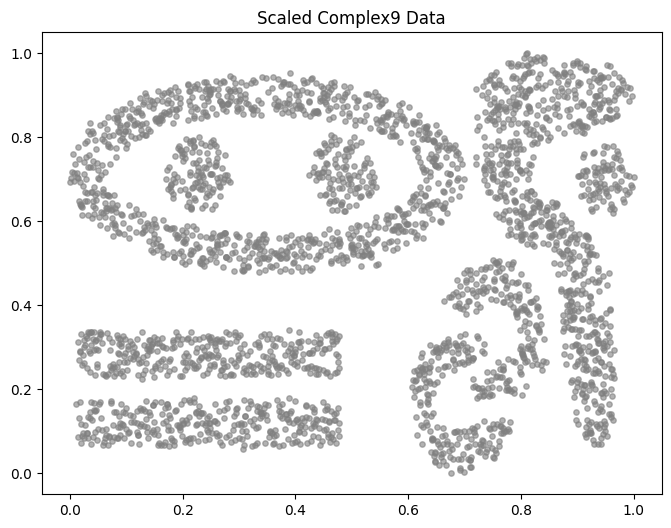

In [83]:
from sklearn.cluster import DBSCAN, KMeans

# 1. Load the complex dataset
X_complex, y_complex = datahandler.load_data("complex9")

print(X_complex[0:5])
print(y_complex[0:5])

# Plot it quickly 
plt.figure(figsize=(8, 6))
plt.scatter(X_complex[:, 0], X_complex[:, 1], s=15, c='gray', alpha=0.6)
plt.title("Scaled Complex9 Data")
plt.show()


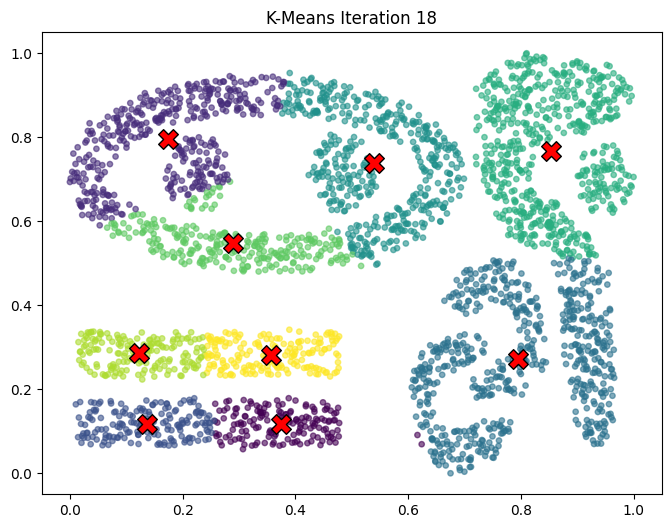

Converged after 18 iterations!


In [84]:
run_interactive_kmeans(X_complex,9, max_iters=300)

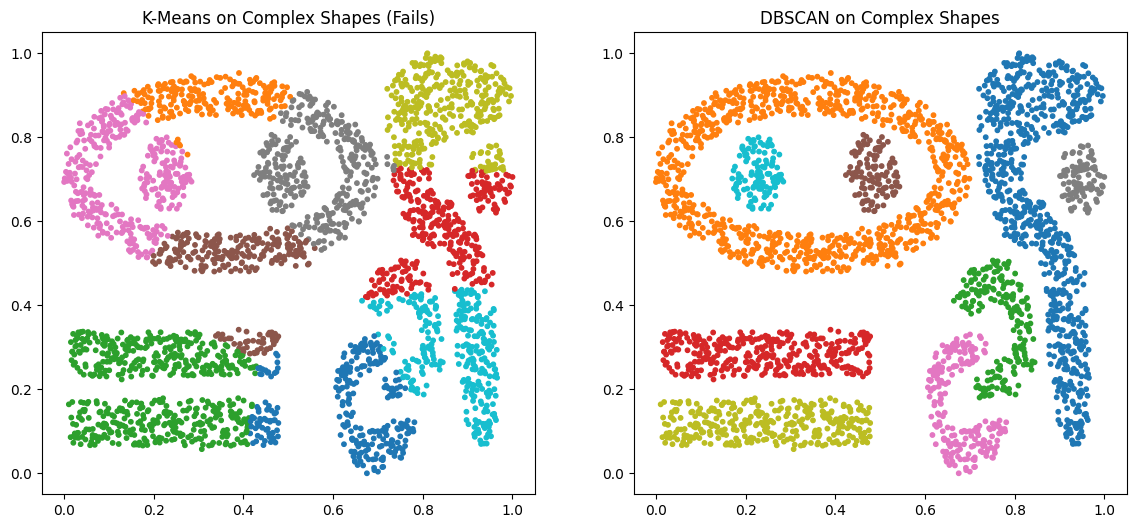

In [85]:
# 2. Run K-Means (Trying to guess 9 clusters)
kmeans = KMeans(n_clusters=9, random_state=42)
kmeans_labels = kmeans.fit_predict(X_complex)

# 3. Run DBSCAN
# Play with eps and min_samples to try and perfectly isolate the 9 shapes!
dbscan = DBSCAN(eps=0.025, min_samples=3) 
dbscan_labels = dbscan.fit_predict(X_complex)

# 4. Plotting the comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X_complex[:, 0], X_complex[:, 1], c=kmeans_labels, cmap='tab10', s=10)
ax1.set_title("K-Means on Complex Shapes (Fails)")

# Note: DBSCAN labels noise as '-1', we color it black
colors = plt.cm.tab10(np.linspace(0, 1, 10))
ax2.scatter(X_complex[:, 0], X_complex[:, 1], c=dbscan_labels, cmap='tab10', s=10)
ax2.set_title("DBSCAN on Complex Shapes")

plt.show()

In [86]:
# Density Peak Clustering (DPC) bridges both appraoches, the rigid centers of K-means and the chaining density of DBSCAN. 
# DPC redefines how we identify the "heart" of a cluster.

# Core Assumptions:
# instead of guessing where a center is (K-means) or just following a dense chain blindly (DBSCAN), DPC analytically calculates what makes a center special. It operates on two foundational assumptions about cluster centers:
#   - Cluster centers are cahracterized by having a higher density than their neighbors
#   - Cluster centers are at a relatively large distance from other points with high densities
#   - Because of these two factors, cluster centers act as local maxima, meaning they are surrounded by neighbors with lower density
# this means that a cluster is efined as a peak in the density of points

# DPC introduces two magical variables rho and delta, in order to find thse peaks, and calcualtes these two metrics for every single point (i) in the dataset:
#   - Local Density (rho_i): this is the number of data points located within a specific cutoff distance (d_c) of point i
#   - Distance (delta_i): this is the minimum distance between point i and any other point that has a higher local density (p)

# Algorithm:
# Once those two numbers are calculated, the algorithm proceeds:
#   1. calculate similariy: First, compute the similarity matrix (d_ij) between all points
#   2. Calculate metrics: compute (rho_i) and (delta_i) for every point
#   3. The Decision Graph: Plot a 2D scatter plot where the X-axis is (rho) and the Y-axis is delta, then select cluster centers. True cluster centers will stand out as massive outliers in the top right corner of this graph (high density AND high Distance)
#   4. The waterfall assignment: assign the remaining non-central points to clusters. instead of K-means iterative reassignment, DPC simply looks at a point and assign it to the same cluster as its nearest, denser neighbor. it cascades down the density gradient instantly
#   5. Outlier Selection: select outliers according to the density border

# Strengths vs Weakness:
#   Strength: It is a one-pass (no optimization required) deterministic algorithm that automatically determines the number of clusters and finds outliers. It also perfectly handles clusters of arbitrary shape and size without restricting them to convex shapes.
# Weaknesses: It has a computational complexity of O(n^2) (though this can be optimized), it struggles with varying densities, and it is sensitive to the cutoff distance parameter (d_c). Furthermore, it usually requires the manual selection of cluster centers.

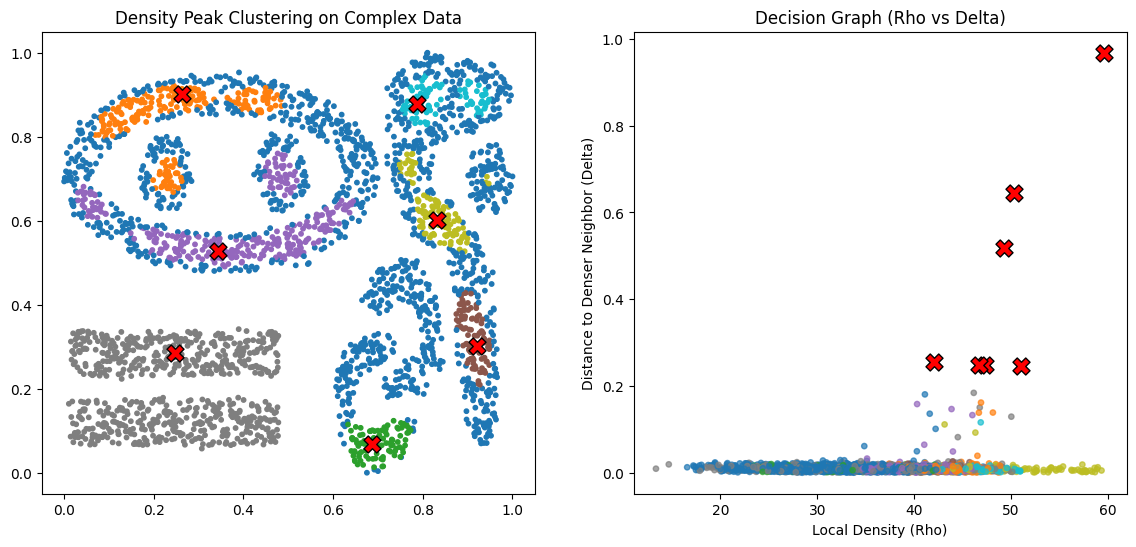

In [87]:
from baseframework.offline_clustering.density_peak_clustering import DensityPeakClustering

# 1. Load the complex data again
X_complex, y_complex = datahandler.load_data("complex9")

# 2. Initialize and fit DPC
# We need to set a distance_threshold (dc). We'll also use the gaussian kernel.
#  might need to tweak the distance_threshold, min_rho, and min_delta!
dpc = DensityPeakClustering(
    metric='euclidean',
    distance_threshold=0.05, 
    gaussian=True,
    min_rho=10,     # A point needs at least this density score to be a peak
    min_delta=0.2   # A point needs to be at least this far from a denser point
)

dpc.fit(X_complex)

# 3. Plotting the results and the Decision Graph
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot the spatial clustering
ax1.scatter(X_complex[:, 0], X_complex[:, 1], c=dpc.labels_, cmap='tab10', s=10)
# Highlight the peaks found by the algorithm
ax1.scatter(X_complex[dpc.density_peaks_, 0], X_complex[dpc.density_peaks_, 1], 
            c='red', marker='X', s=150, edgecolors='black')
ax1.set_title("Density Peak Clustering on Complex Data")

# Plot the Decision Graph
ax2.scatter(dpc.rho_, dpc.delta_, c=dpc.labels_, cmap='tab10', s=15, alpha=0.7)
ax2.scatter(dpc.rho_[dpc.density_peaks_], dpc.delta_[dpc.density_peaks_], 
            c='red', marker='X', s=150, edgecolors='black')
ax2.set_title("Decision Graph (Rho vs Delta)")
ax2.set_xlabel("Local Density (Rho)")
ax2.set_ylabel("Distance to Denser Neighbor (Delta)")

plt.show()

In [88]:
### Adjacency Clustering
# Adjacency clustering is not strictly speaking a single algorithm, but rather an underlying concept
# The Core - Grid Map Analogy
# Imagine we are tracking a million people moving around a city. K-Means,DBSCAN and DPC all try to store the exact GPS coordinates (X and Y) of every single person. This take massive amount ot memory, and every time we calculate a distance, we have to crunch down millions of numbers -> not very efficent in real-time systems

# Adjacency clustering takes a different approach, by drawing a grid over the "city" map. and instead of tracking exact coordinates, the space is organized into so called "Summaries" with extents, like grid cells or radii. As incoming data points arrive, they are simply mapped to these summaries, we do not save any data point into the memory
# we simply read it -> update summary -> and discard

# Steps to form clusters in this paradigm:
#   - Count: we tally up the weight or number of points in each summary (e.g., grid cell)
#   - Filter: we set up a threshhold, such that we can identify all the "dense" summaries (cells with a lot of points in them). 
#     this way we can identify and filter outliers and noise early on and avoid unnecessary computations
#   - Connect: We group connected (adjacent) dense summaries together into clusters. if two dense grid cells are touching each other, they become one big cluster

# This is a game changer!
# Strength:
#   - Extreme efficiency: there is no need to store the individual data points anymore. we only need to track the densities or weights of the summaries!
#   - Incremental Updates: When a new point arrives, it affects only one summary. we don't have to recalculate the whole map! adjacency allows for local updates instead of global computation

# Weakness:
#   - The Goldilocks Problem (Summary Size): It is highly sensetive on the summary size. If the grid cells are too large, we lose detail. if they are too small, it becomes a computational burden
#   - Artificial Boundaries: sometimes "natural" clusters are split artificially by the rigid grid lines. question: can we use different type of grid cells? maybe non sqaured blocks helps fit data better?
# 
# The concept of "summarizing" data into grid cells is exactly how algorithms can manage to survive this bottle neck of infinte barrage of live data stream! 

Algorithm found 9 distinct clusters!


/var/folders/cc/325zq2k937163zqjt1b_rlfr0000gn/T/ipykernel_83718/3074362128.py:56: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(np.unique(labels)))


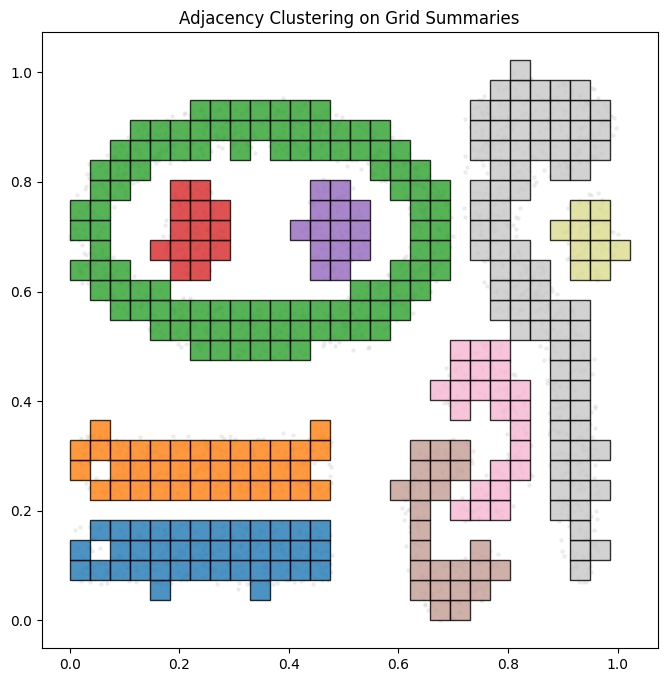

In [89]:
from matplotlib.patches import Rectangle
from baseframework.offline_clustering.adjacency import adjacency_clustering

# 1. Load Data
X, _ = datahandler.load_data("complex9")

# ==========================================
# PHASE 1: "ONLINE" SUMMARIZATION (The Grid)
# ==========================================
grid_size = 0.0365

# Instantly map all points to their grid cell indices
grid_indices = np.floor(X / grid_size).astype(int)

# Count how many points fell into each unique grid cell
unique_cells, counts = np.unique(grid_indices, axis=0, return_counts=True)

# Calculate the actual X/Y center coordinates of these populated grid cells
summary_centers = unique_cells * grid_size + (grid_size / 2)

# Decide the "status" of each summary based on its density (count)
density_threshold = 4
# If a cell has 10 or more points, it's 'dense'. Otherwise, we consider it 'noise'.
status = np.array(["dense" if c >= density_threshold else "noise" for c in counts])

# ==========================================
# PHASE 2: "OFFLINE" ADJACENCY CLUSTERING
# ==========================================
# We want cells that are directly next to each other to connect.
# The distance between two adjacent cell centers is exactly 'grid_size'.
# The adjacency.py script connects points if distance <= sim_thresh[i] + sim_thresh[j]
# So we set the individual threshold to slightly more than half the grid size
sim_thresh = (grid_size / 2) * 1.1


labels = adjacency_clustering(
    X=summary_centers, 
    metric='euclidean', 
    status=status, 
    similarity_thresholds=sim_thresh
)

# number of unique clusters found (ignoring noise label -1)
num_clusters = len(np.unique(labels[labels != -1]))
print(f"Algorithm found {num_clusters} distinct clusters!")

# ==========================================
# PHASE 3: VISUALIZATION
# ==========================================
fig, ax = plt.subplots(figsize=(10, 8))

# 1. Plot the raw deleted data points in the background
ax.scatter(X[:, 0], X[:, 1], c='lightgrey', s=5, alpha=0.3, label="Raw Data (Deleted)")

# 2. Draw the Grid Summaries as colored squares based on their cluster label
cmap = plt.cm.get_cmap('tab20', len(np.unique(labels)))

for i, center in enumerate(summary_centers):
    cluster_id = labels[i]
    if cluster_id == -1:
        continue # Skip noise cells
        
    # Calculate bottom-left corner for the rectangle drawing
    bottom_left = center - (grid_size / 2)
    
    # Draw the grid cell summary
    rect = Rectangle(bottom_left, grid_size, grid_size, 
                     linewidth=1, edgecolor='black', 
                     facecolor=cmap(cluster_id), alpha=0.8)
    ax.add_patch(rect)

ax.set_title("Adjacency Clustering on Grid Summaries")
ax.set_aspect('equal', 'box')
plt.show()

In [90]:
# The Online-Offline Paradigm
# This is is the strategy for dealing with infinte data streams. We cannot wait for the "end" of the data to run an algorithm, and we don't have infinite RAM
# therefore, stream clustering algorithms split the workload into tow main phases:
#   - The Online Phase (Fast & continuous): this is the phase where we process the data continuously as the stream progresses, but it only assigns instances to summary structures 
#     (like grid   cells). It does NOT do the heavy lifting of figuring out the final cluster shapes
#   - The Offline Phase (Slow & Periodic): This is the phase where we take those summaries and run a traditional clustering algorithm on them (e.g., DBSCAN or Adjacency..)
#     this runs independently of the online phase, typically at fixed time inetrvals (T) or when the user requests it

In [91]:
# DStream (Density-Based clustering for real-time stream data) is a classic example of this exact paradign above
# DStream takes the simple grid summerization but it adds the crucial missing dimension for streams: TIME!

# if we have a stream running for a year, a grid cell might have received 1000 points back in January, but zero points since, we want to be able to consider such cases, becasue if we just keep a running total, that cell would forever be considered dense!
# DStream fixes this by introducing Aging.

# 1. The DStream Online Phase (Fading Grid):
# When a new data point (o_i) arrives at time (t_oi):
#   - Map: DStream instantly determines which grid cell the point falls into
#   - Hash: it adds this grid cell to a hash list (for fast-lookups) if it is not already being tracked
#   - Update & Decay: it updates the weight of the grid cell. but in DStream, the weights of all cells constantly decay over time (usually using some decay factor, denoted as lambda)
#     this way older points matter less than newer ones
#   - Status Check: we update the status of the grid cell. Instead of just "Dense" or "Noise" like bfore, DStream caategorizes cells based on their decaying weights into categories like "Dense", "Sparse (noise)" or "Transotional (normal)"

# 2. The DStream Periodic Cleanup (the garbage collector)
# Every T timesteps, the algorithm performs a cleanup:
#   - it looks at the hash list and deletes all grid cells that have become "sporadic" (sparse cells that haven't received any new points recently). this can prevent the computer memory from filling up with old, dead noise

# 3. The DStream Offline Phase (Adjacency):
# This part is usually a traditional clustering algorithm. when clusters are requried, DStream pauses, looks at all the currently "Dense" grid cells, and does exactly what we did earlier and connect adjacent dense cells to form a cluster and arbitrary shapes

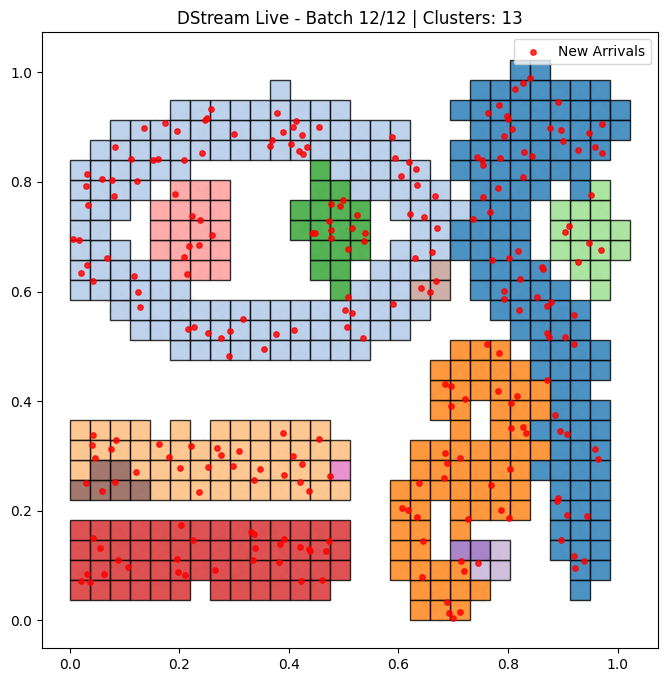

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import clear_output
import time
from baseframework import datahandler
from src.dstream import DStream 

# 1. Load Data
X, _ = datahandler.load_data("complex9")

# 2. Initialize DStream 
grid_sz = 0.0365
# Set cleanup_interval to match your batch size for consistent garbage collection
dstream = DStream(grid_size=grid_sz, decay_factor=0.990, dense_threshold=1.0002, sparse_threshold=0.65, cleanup_interval=500)

batch_size = 250
num_batches = len(X) // batch_size

# Create a fixed colormap so cluster colors stay somewhat consistent
cmap = plt.cm.get_cmap('tab20')

# 3. The Animation Loop
for i in range(num_batches):
    # Slice the current batch
    start_idx = i * batch_size
    end_idx = min((i + 1) * batch_size, len(X))
    batch = X[start_idx:end_idx]
    
    if len(batch) == 0:
        break
        

    timestamps = np.arange(start_idx, end_idx)
    dstream.learn(batch, timestamps)
    
    clustering_dict = dstream.predict()
    
    clear_output(wait=True) # Clears the previous frame
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot the ENTIRE dataset faintly in the background so we see the "goal"
    ax.scatter(X[:, 0], X[:, 1], c='whitesmoke', s=10, zorder=0)
    
    # Plot the CURRENT batch arriving as bright red dots
    ax.scatter(batch[:, 0], batch[:, 1], c='red', s=15, alpha=0.8, label="New Arrivals", zorder=2)
    
    # Draw the Grid Summaries
    for grid_tuple, cluster_id in clustering_dict.items():
        if cluster_id == -1: # Noise / Sparse
            color = 'black'
            alpha = 0.1
        else:
            # Wrap around the colormap if there are many clusters
            color = cmap((cluster_id % 20) / 20.0) 
            alpha = 0.8
            
        # Calculate the bottom-left corner directly from the grid index tuple!
        bottom_left = np.array(grid_tuple) * grid_sz
        
        rect = Rectangle(bottom_left, grid_sz, grid_sz, 
                         linewidth=1, edgecolor='black', 
                         facecolor=color, alpha=alpha, zorder=1)
        ax.add_patch(rect)
    
    # Count unique clusters (ignoring noise label -1)
    unique_clusters = set(val for val in clustering_dict.values() if val != -1)
    num_clusters = len(unique_clusters)
    
    ax.set_title(f"DStream Live - Batch {i+1}/{num_batches} | Clusters: {num_clusters}")
    ax.set_aspect('equal', 'box')
    ax.legend(loc="upper right")
    
    plt.show()
    
    time.sleep(0.5)